##
XGBoost

## Librerias y Configuración

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, classification_report, 
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
#Plantilla de construcción de conjunto de pruebas y testeo

df = pd.read_csv("../data/df_final.csv")

numeric_features = [
    "age", "baseline_bmi", "baseline_charlson_comorbidity_index",
    "systolic_bp_mmhg", "diastolic_bp_mmhg", "heart_rate_bpm",
    "respiratory_rate_bpm", "temperature_celsius", "spo2_percent",
    "blood_glucose_mg_dl", "serum_creatinine_mg_dl", "hemoglobin_g_dl",
    "white_blood_cell_count", "length_of_stay_days", "icu_days",
    "news2_acuity_score", "n_meds", "n_high_risk_meds", "total_drug_cost"
]

categoric_features = [
    "gender", "race_ethnicity", "socioeconomic_tier", "residential_zone",
    "smoker_status", "blood_group", "marital_status", "primary_insurance_provider",
    "encounter_type", "admission_urgency", "department",
    "disease_category", "disease_severity", "procedure_complexity"
]

y = df["readmission_30d"].copy()
X = df[numeric_features + categoric_features]

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")



#Particionmiento de datos en train y test, con estratificación para mantener la proporción de clases en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          
    random_state=42,         
    stratify=y              
)


#Preprocesamiento de daots
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoric_features)
    ],
    remainder="drop"
)



X shape: (13214, 33)
y shape: (13214,)


In [3]:
# MODELO

scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](33,)","['age','baseline_bmi','baseline_charlson_comorbidity_index',..., 'disease_category','disease_severity','procedure_complexity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,33
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [4]:
# PREDICCIONES

y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [5]:
# METRICAS

print("\n--- XGBoost ---")
acc  = accuracy_score(y_test, y_pred_xgb)
prec = precision_score(y_test, y_pred_xgb, zero_division=0)
rec  = recall_score(y_test, y_pred_xgb, zero_division=0)
f1   = f1_score(y_test, y_pred_xgb, zero_division=0)
auc  = roc_auc_score(y_test, y_proba_xgb)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"AUC-ROC  : {auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb,
                            target_names=["No Readmisión (0)", "Readmisión (1)"],
                            zero_division=0))


--- XGBoost ---
Accuracy : 0.6746
Precision: 0.5056
Recall   : 0.6747
F1-score : 0.5780
AUC-ROC  : 0.7406

Classification Report:
                   precision    recall  f1-score   support

No Readmisión (0)       0.81      0.67      0.74      1770
   Readmisión (1)       0.51      0.67      0.58       873

         accuracy                           0.67      2643
        macro avg       0.66      0.67      0.66      2643
     weighted avg       0.71      0.67      0.68      2643



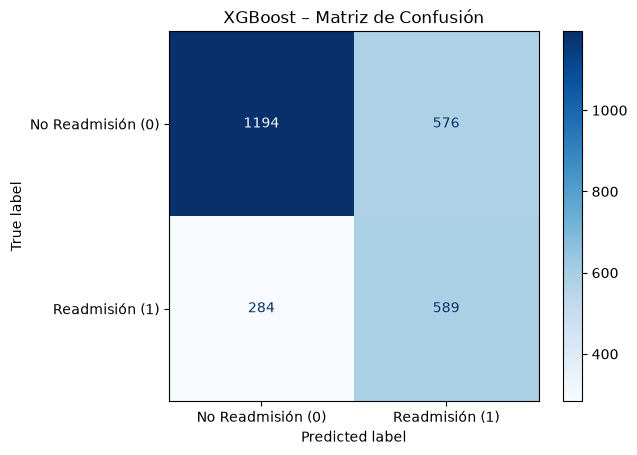

In [6]:
#MATRIZ DE CONFUSIÓN

cm = confusion_matrix(y_test, y_pred_xgb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["No Readmisión (0)", "Readmisión (1)"])
disp.plot(cmap="Blues")
plt.title("XGBoost – Matriz de Confusión")
plt.show()